<a href="https://colab.research.google.com/github/Lupo6789/tesi_scacchi/blob/main/04_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 3. Model Selection e Architettura di Validazione

In questa sezione si definisce l'impianto metodologico per il confronto e la selezione del miglior algoritmo predittivo tra Regressione Logistica, Random Forest e LightGBM. Il codice implementa i seguenti vincoli strutturali:

**Isolamento del Test Set e Cross-Validation**
Il confronto tra i modelli avviene caricando esclusivamente il Train Set. Le prestazioni non vengono misurate su una singola previsione, ma stimate tramite una *Stratified 5-Fold Cross-Validation*. Questo approccio restituisce la media aritmetica e la deviazione standard per ciascuna metrica (Accuracy, ROC-AUC, Log-Loss), utili a valutare oltre che il punteggio assoluto, anche la syabilità e incertezza statistica del modello preso in esame.

**2. Feature Engineering Mirata (rating_diff)**
Prima dell'addestramento, viene calcolata e inserita esplicitamente la variabile `rating_diff` (differenza di punteggio Elo tra Bianco e Nero). Essa è utile principalmente agli algoritmi ad albero quali Random Forest e LightGBM che necessitano di un dato esplicito per lavorare

**3. Calcolo della Baseline Dinamica**
Poiché al crescere della soglia N il campione statistico diminuisce in numero(rimangono solo le partite più lunghe), il potere predittivo del solo sistema di rating subisce una variazione. Il codice ricalcola dinamicamente a ogni ciclo una *Baseline* (Regressione Logistica addestrata esclusivamente su rating_diff). Questo permette di misurare in modo esatto il "Guadagno", ovvero l'aumento netto di potere predittivo (ROC-AUC) fornito esclusivamente dall'estrazione delle feature posizionali ricavate dall'andamento della partita sulla scacchiera.

**4. Configurazione dei Modelli**
I modelli ad albero vengono istanziati con i parametri di default e meccanismi di blocco base per l'overfitting (min_samples_leaf=20 per il Random Forest per esempio). La Regressione Logistica viene incapsulata in una Pipeline con uno `StandardScaler` per standardizzare i dati in ingresso e uniformare la scala numerica delle feature posizionali, se non operassi in questo modo i valori sarebbero tutti "sballati"  e non più comparabili.



 NOTEBOOK 04: MODEL SELECTION E CROSS-VALIDATION SUL TRAIN SET

Addestramento in Cross-Validation in corso

Valutazione modelli per N=10...
Valutazione modelli per N=20...
Valutazione modelli per N=30...
Valutazione modelli per N=40...

 RISULTATI CROSS-VALIDATION (5-Fold) 
 N             Modello      Accuracy       ROC-AUC      Log-Loss Guadagn vs Base
10 Logistic Regression 0.650 ± 0.006 0.715 ± 0.006 0.616 ± 0.004          +0.002
10       Random Forest 0.646 ± 0.006 0.713 ± 0.009 0.615 ± 0.005          +0.000
10            LightGBM 0.646 ± 0.006 0.707 ± 0.007 0.621 ± 0.005          -0.006
20 Logistic Regression 0.669 ± 0.006 0.736 ± 0.008 0.600 ± 0.006          +0.026
20       Random Forest 0.665 ± 0.007 0.734 ± 0.009 0.600 ± 0.006          +0.025
20            LightGBM 0.660 ± 0.009 0.728 ± 0.009 0.607 ± 0.006          +0.019
30 Logistic Regression 0.687 ± 0.007 0.762 ± 0.011 0.577 ± 0.011          +0.057
30       Random Forest 0.692 ± 0.011 0.762 ± 0.010 0.578 ± 0.008          +0.

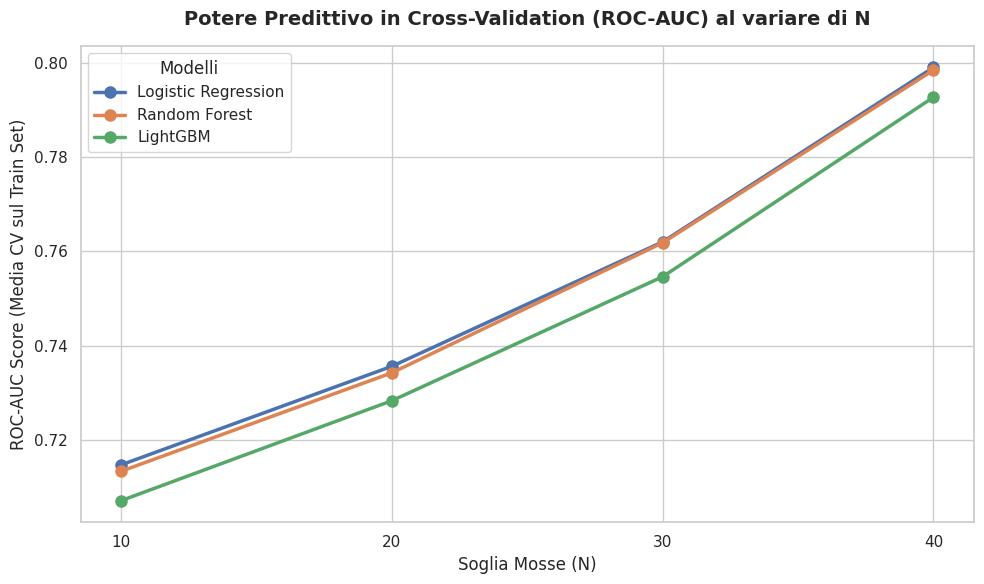

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
import warnings

print(" NOTEBOOK 04: MODEL SELECTION E CROSS-VALIDATION SUL TRAIN SET\n")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Modelli con i parametri suggeriti
modelli = {
    'Logistic Regression': Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000))]),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1),
}

righe = []
# Serve per salvare i dati per il grafico (basato sulla media CV)
risultati_plot = {'N': [10, 20, 30, 40], 'Logistic Regression': [], 'Random Forest': [], 'LightGBM': []}

print("Addestramento in Cross-Validation in corso\n")

for N in [10, 20, 30, 40]:
    print(f"Valutazione modelli per N={N}...")

    #Carico solo il Train Set
    df = pd.read_csv(f'train_features_N{N}.csv').dropna()

    # Feature Engineering essenziale: rating_diff aiuta enormemente i modelli ad albero
    df['rating_diff'] = df['white_rating'] - df['black_rating']

    y = df['winner']

    # Pulizia colonne: Rimuoviamo il target e gli ID dei giocatori per evitare leakage
    colonne_da_escludere = ['winner', 'id', 'white_id', 'black_id']
    X = df.drop(columns=[c for c in colonne_da_escludere if c in df.columns])

    # Calcolo rapido della Baseline (LogReg solo su rating_diff, come nel Notebook 03)
    # Serve per calcolare di quanto miglioriamo rispetto all'uso del solo Elo per questa specifica soglia N.
    res_base = cross_validate(modelli['Logistic Regression'], df[['rating_diff']], y, cv=cv, scoring='roc_auc')
    auc_base_mean = res_base['test_score'].mean()

    # 3. Addestramento in CV per i modelli completi
    for nome, m in modelli.items():
        r = cross_validate(m, X, y, cv=cv, scoring=['accuracy', 'roc_auc', 'neg_log_loss'])

        auc_mean = r['test_roc_auc'].mean()
        auc_std = r['test_roc_auc'].std()
        acc_mean = r['test_accuracy'].mean()
        acc_std = r['test_accuracy'].std()
        loss_mean = -r['test_neg_log_loss'].mean() #metto meno perchè torna positivo
        loss_std = r['test_neg_log_loss'].std()

        # Guadagno rispetto alla Baseline pura (Solo Elo)
        guadagno = auc_mean - auc_base_mean

        righe.append({
            'N': N,
            'Modello': nome,
            'Accuracy': f"{acc_mean:.3f} ± {acc_std:.3f}",
            'ROC-AUC': f"{auc_mean:.3f} ± {auc_std:.3f}",
            'Log-Loss': f"{loss_mean:.3f} ± {loss_std:.3f}",
            'Guadagn vs Base': f"+{guadagno:.3f}" if guadagno > 0 else f"{guadagno:.3f}"
        })

        # Salvataggio media AUC per il grafico
        risultati_plot[nome].append(auc_mean)

print("\n RISULTATI CROSS-VALIDATION (5-Fold) ")
df_risultati = pd.DataFrame(righe)
print(df_risultati.to_string(index=False))

# 4. Creazione del Grafico (Plot ROC-AUC in CV)
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

for modello in modelli.keys():
    plt.plot(risultati_plot['N'], risultati_plot[modello], marker='o', linewidth=2.5, markersize=8, label=modello)

plt.title("Potere Predittivo in Cross-Validation (ROC-AUC) al variare di N", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Soglia Mosse (N)", fontsize=12)
plt.ylabel("ROC-AUC Score (Media CV sul Train Set)", fontsize=12)
plt.xticks([10, 20, 30, 40])
plt.legend(title="Modelli", fontsize=11, title_fontsize=12)
plt.tight_layout()
plt.show()

### Analisi dei Risultati in Cross-Validation
I risultati dell'analisi numerica delle metriche ci rivelano diverse informazioni importanti:

**1. Validazione delle Feature Posizionali e "Gain" vs Baseline**
Si osserva un marcato e costante incremento del potere predittivo per tutti gli algoritmi al progredire della partita. Passando dalla fase di apertura (N=10) al mediogioco (N=40), la metrica ROC-AUC generale cresce da circa 0.71 a 0.79, accompagnata da una crescita dell'Accuracy (fino al 71.9%) e da un crollo della Log-Loss (da 0.616 a 0.542), testimoniando una crescente certezza probabilistica nelle previsioni.
Il dato più rilevante è però il *Gain vs Base*: a N=10 l'apporto delle feature è nullo (+0.002) poiché la scacchiera è quasi invariata, le mosse effettuate sono ancora poche. A N=40, invece, il guadagno esplode a +0.100: ciò certifica il successo del feature engineering, dimostrando che l'estrazione di variabili posizionali (vantaggio materiale, mobilità) aumentano del 10% l'accuratezza del modello rispetto al guardare esclusivamente il divario Elo.

**2. Parità Statistica tra i Modelli**
Confrontando le performance sul Train Set, si osserva che i divari tra la Regressione Logistica e i modelli ad albero rientrano ampiamente nei margini della deviazione standard. A N=40, ad esempio, la Regressione Logistica registra un'AUC di 0.799 ± 0.010, seguita dal Random Forest con 0.798 ± 0.009. La differenza millesimale (0.001) impedisce di dichiarare una netta superiorità della RegLog, confermando piuttosto una parità statistica. La Logistica si conferma tuttavia un *benchmark* formidabile, grazie alla natura intrinsecamente lineare e additiva del vantaggio materiale negli scacchi.

**3. L'importanza strutturale di `rating_diff`**
Il pareggio prestazionale raggiunto dal Random Forest certifica l'importanza di aver calcolato esplicitamente la variabile `rating_diff